# Ridge model on surprise features

**Competition metric.** ΔR² = R²(`target_pct` ~ prediction + surprise) − R²(`target_pct` ~ surprise), both OLS with an intercept, where the surprise is `earnings_surprise_pct`: the EPS surprise ranked within the quarter (rank / N over events with a valid value). Koijen and Levy (§2.3.3) rank it "to curb the impact of outliers"; on the raw value a few extreme surprises dominate and the surprise-only R² is near 0, while ranked it reproduces their 5.0% for 2025Q4 (4.9% here). A prediction scores only for what it explains beyond the ranked surprise.

**Run 2.** Run 1 used the raw surprise as the control and chose alpha by the mean of per-fold ΔR²; its notebook and outputs are kept in `data/surprise/runs/run1_raw_control/`. This run uses the ranked control and selects by pooled out-of-fold ΔR². Test has been scored once before (run 1), so read this test result next to that one.

**Plan.**
1. Missing values: what is missing and how it is handled.
2. Reference scores on train: single features and the competition baselines.
3. Ridge hyperparameters by time-ordered cross-validation on train (alpha, feature set, target mode, log transform), chosen by pooled out-of-fold ΔR².
4. Fit the chosen configuration on all train events.
5. Evaluate once on test with ΔR², against the competition baselines and the plain `net_w` score, with paired bootstrap comparisons.

Data: `data/surprise/features_v2.csv` (1,076 train events, 3–13 Aug 2026; 289 test events, 13 Aug–22 Sep).

In [1]:
%load_ext autoreload
%autoreload 2

import json

import numpy as np
import pandas as pd

from ml import metrics, model, preprocess
from suprise_dim import data, features

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

feat = pd.read_csv(features.features_path("v2"))
train = feat[feat["split"] == "train"].reset_index(drop=True)
test = feat[feat["split"] == "test"].reset_index(drop=True)
BASELINES = sorted(c for c in feat.columns if c.startswith("baseline__"))
ES = model.ES  # "earnings_surprise_pct", the ranked control
print(f"train {len(train)} | test {len(test)} | baselines: {[b.split('__')[1] for b in BASELINES]}")

train 1076 | test 289 | baselines: ['deepseek', 'gemini', 'moonshotai', 'openai', 'z-ai']


## 1. Missing values

- **Surprise features** are complete: a dimension with no surprise scores 0, and the 18 test events whose call facts have no content are all zeros with `no_surprises = 1`.
- **Option statistics** are missing for most events. Inside the model they are imputed with the training-fold median plus a missing-value indicator (`preprocess.build_preprocessor`), fitted on training rows only.
- **`earnings_surprise` / `earnings_surprise_pct`** are missing where the archive has no EPS. They are not model inputs. In the metric, rows without the ranked surprise are dropped (the count is reported). The `residual` target mode imputes the training median of the ranked surprise to residualize.
- **Baselines** are missing for some events, so comparisons use rows where every prediction exists.

In [2]:
cols = preprocess.OPTION_COLUMNS + ["earnings_surprise", ES] + BASELINES
preprocess.missing_summary(feat, cols)

split,test,train,all
opt_implied_earnings_volatility,0.536,0.586,0.575
opt_implied_absolute_earnings_move,0.536,0.586,0.575
opt_skew_25_delta,0.626,0.767,0.737
earnings_surprise,0.062,0.045,0.048
earnings_surprise_pct,0.062,0.045,0.048
baseline__deepseek,0.024,0.017,0.018
baseline__gemini,0.007,0.000,0.001
baseline__moonshotai,0.010,0.042,0.035
baseline__z-ai,0.017,0.008,0.010


## 2. Reference scores on train

Single features turned into percentiles by rank, and the competition baselines. These show the scale of ΔR² before any model is fitted.

In [3]:
def references(frame):
    refs = {name: model.rank_to_percentile(frame[name]) for name in ["net_w", "net_w_first3", "net"]}
    refs |= {b.split("__")[1]: frame[b].to_numpy() for b in BASELINES}
    return refs

metrics.evaluate(train["target_pct"], references(train), train[ES]).round(4)

,n,r2_base,r2_full,delta_r2,spearman
net_w,1028.0,0.0730,0.2411,0.1681,0.4676
net_w_first3,1028.0,0.0730,0.2358,0.1628,0.4658
net,1028.0,0.0730,0.2230,0.1500,0.4427
gemini,1028.0,0.0730,0.2103,0.1373,0.3984
z-ai,1019.0,0.0725,0.1978,0.1253,0.3734
deepseek,1011.0,0.0755,0.1967,0.1212,0.3704
moonshotai,985.0,0.0749,0.1802,0.1053,0.3541
openai,1028.0,0.0730,0.1575,0.0845,0.3201


## 3. Cross-validation on train

Expanding-window folds in time order (`model.time_folds`, 5 folds; fold k trains on the earliest blocks and validates on the next). Each configuration is scored by ΔR² on every validation fold (mean and sd) and on the pooled out-of-fold predictions. **Selection uses the pooled score:** ΔR² ignores a prediction's scale, so the mean of per-fold scores keeps rising as alpha shrinks predictions toward a constant (run 1 picked the largest alpha in the grid), while pooling across folds penalizes that.

Grid:
- `feature_set`: `totals`, `net` (per-dimension net), `posneg` (per-dimension positive and negative), `all`
- `alpha`: 0.1 to 10,000 on a log scale
- `target_mode`: `raw` (fit `target_pct`) or `residual` (fit what the ranked surprise leaves unexplained)
- `log_counts`: signed log of count features, or not

In [4]:
sets = preprocess.feature_sets(feat.columns)
print({name: len(cols) for name, cols in sets.items()})

alphas = np.logspace(-1, 4, 11)
grid = model.grid_search(train, sets, alphas)
grid.drop(columns="fold_delta_r2").head(15).round(4)

{'totals': 10, 'net': 22, 'posneg': 37, 'all': 59}


,feature_set,n_features,alpha,target_mode,log_counts,cv_delta_r2_mean,cv_delta_r2_sd,oof_delta_r2,oof_spearman
0,all,59,1000.0000,raw,False,0.2019,0.0783,0.1829,0.4906
1,all,59,1000.0000,residual,False,0.1991,0.0722,0.1814,0.4800
2,all,59,3162.2777,residual,False,0.2090,0.0800,0.1795,0.4888
3,all,59,1000.0000,raw,True,0.1972,0.0798,0.1779,0.4819
4,all,59,3162.2777,raw,False,0.2086,0.0822,0.1777,0.4921
5,all,59,1000.0000,residual,True,0.1945,0.0733,0.1766,0.4699
6,totals,10,100.0000,raw,False,0.1911,0.0828,0.1763,0.4872
7,totals,10,100.0000,residual,False,0.1897,0.0834,0.1758,0.4865
8,totals,10,316.2278,residual,False,0.1926,0.0835,0.1749,0.4883
9,all,59,3162.2777,residual,True,0.2039,0.0805,0.1749,0.4767


In [5]:
# Best configuration per feature set and per target mode, to see what drives the score.
summary = grid.drop(columns="fold_delta_r2")
display(summary.groupby("feature_set").head(1).round(4))
summary.groupby("target_mode").head(1).round(4)

,feature_set,n_features,alpha,target_mode,log_counts,cv_delta_r2_mean,cv_delta_r2_sd,oof_delta_r2,oof_spearman
0,all,59,1000.0000,raw,False,0.2019,0.0783,0.1829,0.4906
6,totals,10,100.0000,raw,False,0.1911,0.0828,0.1763,0.4872
15,posneg,37,316.2278,raw,False,0.1846,0.0715,0.1717,0.4756
16,net,22,316.2278,raw,False,0.1869,0.0709,0.1706,0.4755


,feature_set,n_features,alpha,target_mode,log_counts,cv_delta_r2_mean,cv_delta_r2_sd,oof_delta_r2,oof_spearman
0,all,59,1000.0,raw,False,0.2019,0.0783,0.1829,0.4906
1,all,59,1000.0,residual,False,0.1991,0.0722,0.1814,0.4800


### Chosen configuration

The top row by pooled out-of-fold ΔR². With ~200 configurations on 1,076 events the winner's CV score is optimistic, so the test score below is the number to trust.

In [6]:
best = grid.iloc[0]
print(best.drop("fold_delta_r2").to_dict())
print("fold ΔR²:", np.round(best["fold_delta_r2"], 4))

{'feature_set': 'all', 'n_features': 59, 'alpha': 1000.0, 'target_mode': 'raw', 'log_counts': False, 'cv_delta_r2_mean': 0.2018697422322097, 'cv_delta_r2_sd': 0.07825849902998981, 'oof_delta_r2': 0.18292241045714208, 'oof_spearman': 0.4906394036035579}
fold ΔR²: [0.1479 0.2955 0.1617 0.277  0.1273]


## 4. Fit on all train events

In [7]:
final = model.fit(train, sets[best["feature_set"]], best["alpha"],
                  target_mode=best["target_mode"], log_counts=bool(best["log_counts"]))
train_pred = final.predict(train)
print("train (in-sample) ΔR²:", round(metrics.delta_r2(train["target_pct"], train_pred, train[ES])["delta_r2"], 4))
final.coefficients().head(20).round(4).to_frame("coef")

train (in-sample) ΔR²: 0.2102


,coef
net_w_first3,0.0202
neg_w__forward_guidance,-0.0199
net_first3,0.0168
net_w__forward_guidance,0.0155
net_w,0.0139
pos_w__operating_profitability,0.0113
net_per_item,0.0109
net_w__operating_profitability,0.0104
neg_w__capital_allocation,0.0099
net,0.0096


## 5. Test evaluation

All predictions are compared on the same rows: test events with the ranked surprise and every baseline present.

In [8]:
test_pred = final.predict(test)
preds = {"ridge": test_pred} | references(test)

common = test[[ES] + BASELINES].notna().all(axis=1).to_numpy()
print(f"test rows: {len(test)} | with the ranked surprise and all baselines: {common.sum()}")
metrics.evaluate(test["target_pct"][common], {k: v[common] for k, v in preds.items()}, test[ES][common]).round(4)

test rows: 289 | with the ranked surprise and all baselines: 256


,n,r2_base,r2_full,delta_r2,spearman
net_w_first3,256.0,0.1384,0.2687,0.1303,0.4680
ridge,256.0,0.1384,0.2674,0.1290,0.4543
net,256.0,0.1384,0.2419,0.1036,0.4030
net_w,256.0,0.1384,0.2378,0.0994,0.4086
z-ai,256.0,0.1384,0.2088,0.0704,0.3022
gemini,256.0,0.1384,0.2055,0.0672,0.3005
moonshotai,256.0,0.1384,0.1972,0.0589,0.2939
openai,256.0,0.1384,0.1898,0.0514,0.2741
deepseek,256.0,0.1384,0.1840,0.0457,0.2811


In [9]:
# Each prediction on every test row it can be scored on (n differs by prediction).
metrics.evaluate(test["target_pct"], preds, test[ES]).round(4)

,n,r2_base,r2_full,delta_r2,spearman
ridge,271.0,0.1236,0.2391,0.1155,0.4152
net_w_first3,271.0,0.1236,0.2383,0.1147,0.4171
net,271.0,0.1236,0.2158,0.0922,0.3838
net_w,271.0,0.1236,0.2105,0.0869,0.3811
z-ai,266.0,0.1321,0.2058,0.0737,0.3039
gemini,270.0,0.1212,0.1841,0.0629,0.2816
deepseek,264.0,0.1327,0.1799,0.0473,0.2796
moonshotai,268.0,0.1219,0.1677,0.0458,0.2631
openai,271.0,0.1236,0.1631,0.0395,0.2397


In [10]:
# Paired bootstrap on the common rows: ridge minus each other prediction.
samples = metrics.paired_bootstrap(test["target_pct"][common], {k: v[common] for k, v in preds.items()},
                                   test[ES][common], n_boot=2000, seed=0)
print("ridge ΔR² 95% interval:", samples["ridge"].quantile([0.025, 0.975]).round(4).tolist())
metrics.compare_to(samples, "ridge").round(4)

ridge ΔR² 95% interval: [0.0646, 0.2093]


,mean_diff,ci_low,ci_high,P(ridge better)
net_w,0.0293,0.0000,0.0577,0.9750
net_w_first3,-0.0017,-0.0411,0.0361,0.4760
net,0.0251,-0.0067,0.0557,0.9445
deepseek,0.0838,0.0297,0.1427,0.9995
gemini,0.0625,0.0110,0.1208,0.9915
moonshotai,0.0710,0.0159,0.1298,0.9935
openai,0.0776,0.0197,0.1436,0.9965
z-ai,0.0591,-0.0029,0.1284,0.9665


### Predicted vs actual percentile

Every test event (n = 289), ridge prediction against the actual `target_pct`.

- **Left, raw scale:** the predictions themselves. Ridge pulls them toward the middle (most fall between 0.3 and 0.75). The line is an OLS fit of prediction on actual percentile.
- **Right, ranked:** the same predictions turned into percentiles within the test set. ΔR² and Spearman depend only on this ordering, so here a perfect model would sit on the diagonal.

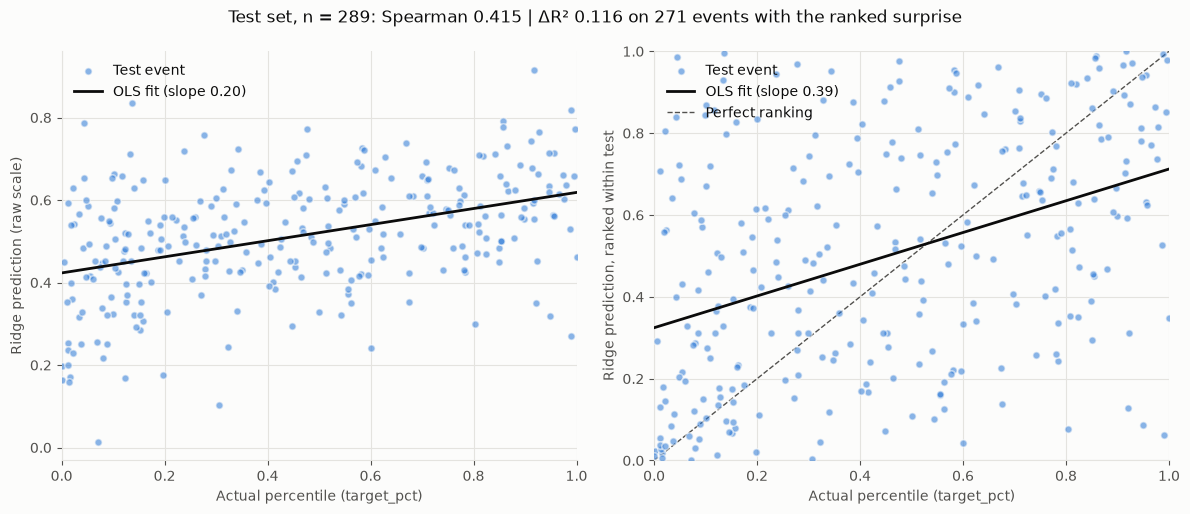

In [11]:
import matplotlib.pyplot as plt

SERIES, INK, MUTED, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

actual = test["target_pct"].to_numpy()
pred_rank = model.rank_to_percentile(test_pred)
grid_x = np.array([0.0, 1.0])
stats = metrics.delta_r2(test["target_pct"], test_pred, test[ES])
rho = metrics.spearman(test_pred, actual)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), facecolor=SURFACE)
for ax, y, title in [(axes[0], test_pred, "Ridge prediction (raw scale)"),
                     (axes[1], pred_rank, "Ridge prediction, ranked within test")]:
    ax.set_facecolor(SURFACE)
    ax.scatter(actual, y, s=28, color=SERIES, alpha=0.55, edgecolors=SURFACE, linewidths=1.2, label="Test event", zorder=3)
    slope, intercept = np.polyfit(actual, y, 1)
    ax.plot(grid_x, intercept + slope * grid_x, color=INK, linewidth=2, label=f"OLS fit (slope {slope:.2f})", zorder=4)
    if ax is axes[1]:
        ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--", label="Perfect ranking", zorder=2)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Actual percentile (target_pct)", color=MUTED)
    ax.set_ylabel(title, color=MUTED)
    ax.grid(color=GRID, linewidth=0.8)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.legend(frameon=False, loc="upper left", labelcolor=INK)
axes[1].set_ylim(0, 1)

fig.suptitle(f"Test set, n = {len(test)}: Spearman {rho:.3f} | ΔR² {stats['delta_r2']:.3f} on {stats['n']} events with the ranked surprise",
             color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(data.OUT_DIR / "ridge_v2_test_pred_vs_actual.png", dpi=150, facecolor=SURFACE)
plt.show()

## 6. Save test predictions and the chosen configuration

In [12]:
out = test[["event_id", "event_datetime", "target_pct", "earnings_surprise", ES]].assign(ridge=test_pred)
out.to_csv(data.OUT_DIR / "ridge_v2_test_predictions.csv", index=False)

config = {k: (v.item() if hasattr(v, "item") else v) for k, v in best.drop("fold_delta_r2").to_dict().items()}
config["features"] = final.features
(data.OUT_DIR / "ridge_v2_config.json").write_text(json.dumps(config, indent=2))
print(config | {"features": f"{len(final.features)} columns"})

{'feature_set': 'all', 'n_features': 59, 'alpha': 1000.0, 'target_mode': 'raw', 'log_counts': False, 'cv_delta_r2_mean': 0.2018697422322097, 'cv_delta_r2_sd': 0.07825849902998981, 'oof_delta_r2': 0.18292241045714208, 'oof_spearman': 0.4906394036035579, 'features': '59 columns'}
